# Question 6: DFT-based Image Compression

The image is processed independently on 32 x 32 pixel blocks. Within each block, Fourier coefficients with magnitude at most `Fmax * tol` are set to zero.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

plt.rcParams['axes.grid'] = False
f = np.array(mpimg.imread('operahall.png'), dtype=float)
if f.ndim == 3:
    f = f[..., 0]
print('Image shape:', f.shape)
print('Pixel range:', f.min(), 'to', f.max())

Image shape: (512, 512)
Pixel range: 0.0 to 1.0


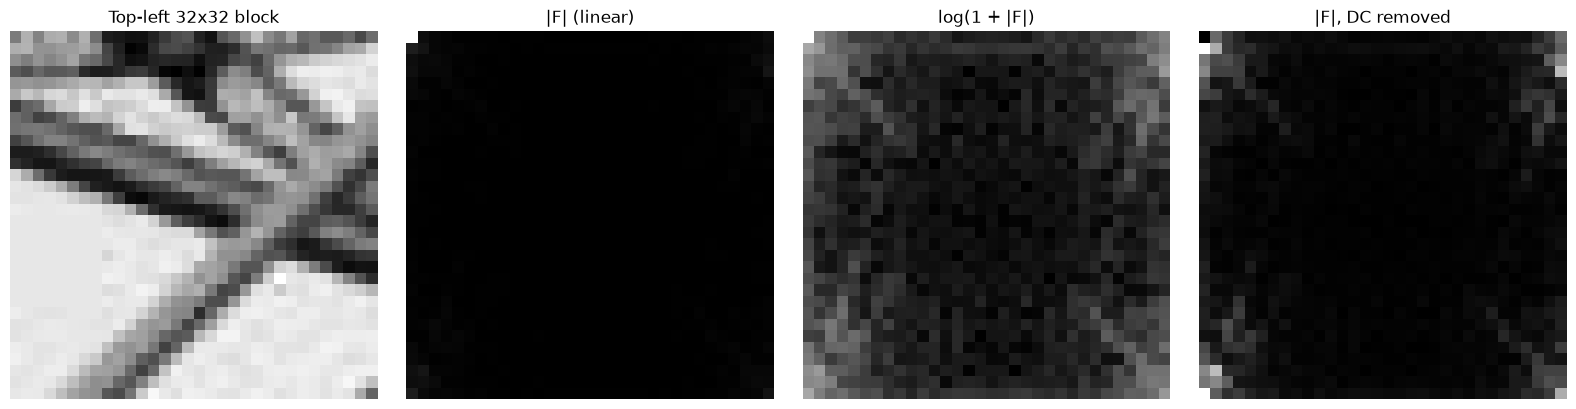

Brightest pixel in |F|: row 0, column 0
|F| at that pixel: 519.235308
F[0,0] = (519.2353082075715+0j)
sum of block pixels = 519.2353082075715


In [2]:
block = f[:32, :32]
F = np.fft.fft2(block)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(block, cmap='gray')
axes[0].set_title('Top-left 32x32 block')
axes[1].imshow(np.abs(F), cmap='gray')
axes[1].set_title('|F| (linear)')
axes[2].imshow(np.log1p(np.abs(F)), cmap='gray')
axes[2].set_title('log(1 + |F|)')
F_no_dc = F.copy()
F_no_dc[0, 0] = 0
axes[3].imshow(np.abs(F_no_dc), cmap='gray')
axes[3].set_title('|F|, DC removed')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig('q6_block.png', dpi=150, bbox_inches='tight')
plt.show()

brightest = np.unravel_index(np.argmax(np.abs(F)), F.shape)
print('Brightest pixel in |F|: row %d, column %d' % brightest)
print('|F| at that pixel: %.6f' % np.abs(F[brightest]))
print('F[0,0] =', F[0, 0])
print('sum of block pixels =', block.sum())

In [3]:
def Compress(X, tol):
    """Compress an image by thresholding Fourier coefficients on 32x32 blocks."""
    X = np.asarray(X, dtype=float)
    H, W = X.shape
    bs = 32
    assert H % bs == 0 and W % bs == 0, 'image dimensions must be multiples of 32'
    Y = np.zeros_like(X)
    total_nonzero = 0
    dropped_nonzero = 0
    for i in range(0, H, bs):
        for j in range(0, W, bs):
            block = X[i:i + bs, j:j + bs]
            F = np.fft.fft2(block)
            mag = np.abs(F)
            threshold = mag.max() * tol
            keep = mag > threshold
            total_nonzero += int(np.count_nonzero(mag))
            dropped_nonzero += int(np.count_nonzero((mag > 0) & (~keep)))
            Y[i:i + bs, j:j + bs] = np.real(np.fft.ifft2(F * keep))
    drop = dropped_nonzero / total_nonzero if total_nonzero else 0.0
    return Y, drop

tol = 0.0010, drop ratio = 0.4936
tol = 0.0040, drop ratio = 0.7997
tol = 0.0094, drop ratio = 0.9202
tol = 0.0200, drop ratio = 0.9699


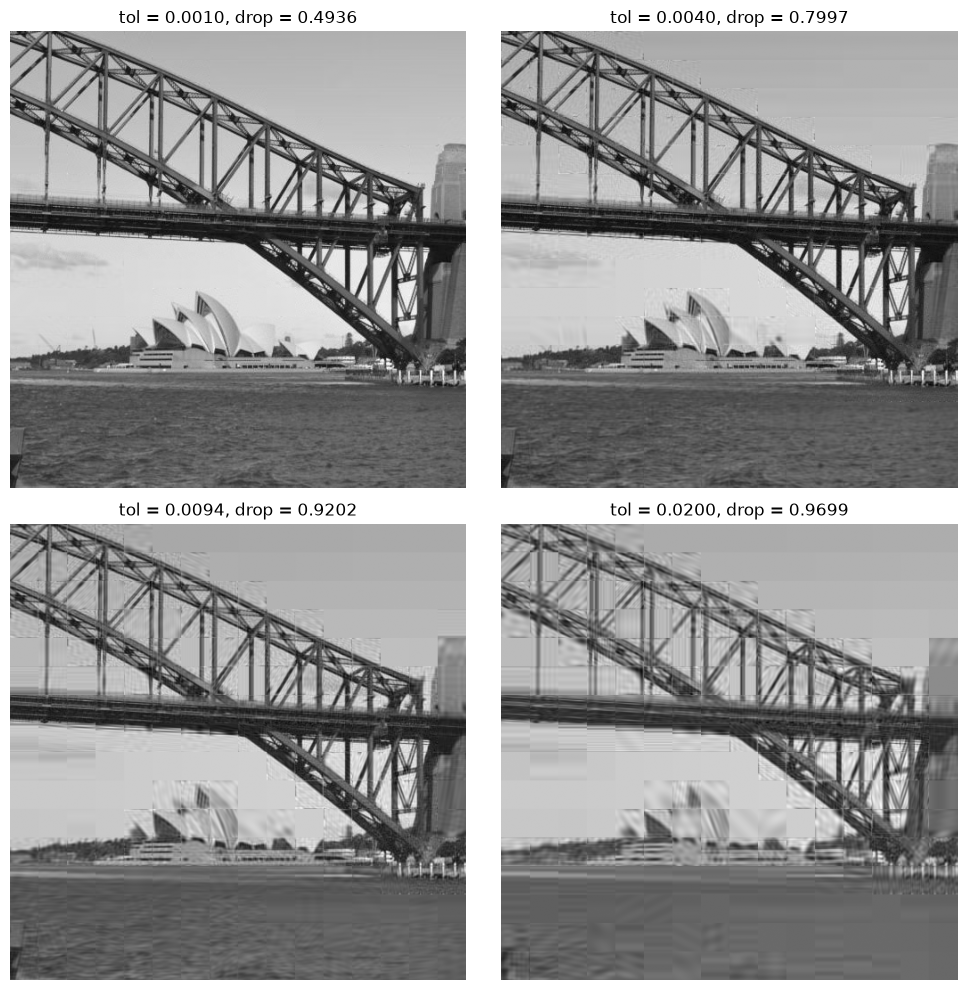

In [4]:
# Tolerances chosen by trial and error to give the requested drop ratios.
tols = [0.0010, 0.0040, 0.0094, 0.020]
results = []

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for ax, tol in zip(axes.flat, tols):
    Y, drop = Compress(f, tol)
    results.append((tol, Y, drop))
    print(f'tol = {tol:.4f}, drop ratio = {drop:.4f}')
    ax.imshow(Y, cmap='gray')
    ax.set_title(f'tol = {tol:.4f}, drop = {drop:.4f}')
    ax.axis('off')
plt.tight_layout()
plt.savefig('q6_compressed.png', dpi=150, bbox_inches='tight')
plt.show()

Least compressed image: tol = 0.0010, drop = 0.4936
Mean absolute error = 0.003494
Maximum absolute error = 0.411966


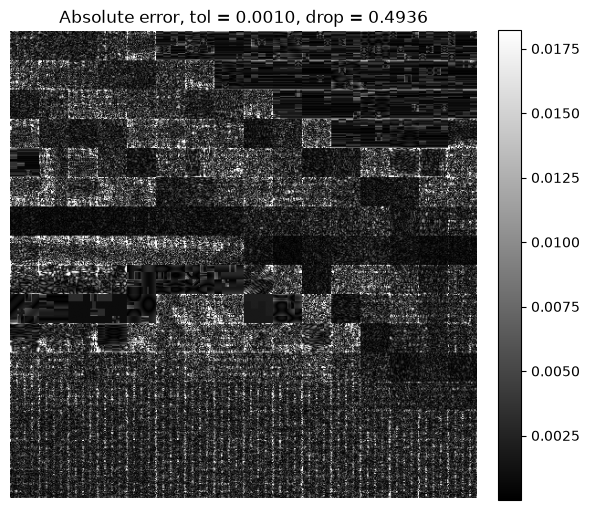

In [5]:
tol, Y_least, drop_least = results[0]
err = np.abs(f - Y_least)
print(f'Least compressed image: tol = {tol:.4f}, drop = {drop_least:.4f}')
print(f'Mean absolute error = {err.mean():.6f}')
print(f'Maximum absolute error = {err.max():.6f}')

plt.figure(figsize=(6, 6))
plt.imshow(err, cmap='gray', vmax=np.percentile(err, 99))
plt.title(f'Absolute error, tol = {tol:.4f}, drop = {drop_least:.4f}')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')
plt.tight_layout()
plt.savefig('q6_error.png', dpi=150, bbox_inches='tight')
plt.show()